Задание. Найти энергию и волновую функцию основного состояния для указанного
в варианте стационарного уравнения Шрёдингера двумя способами: с помощью функции
solve_bvp и метода стрельбы. Сравнить результаты, полученные обоими методами
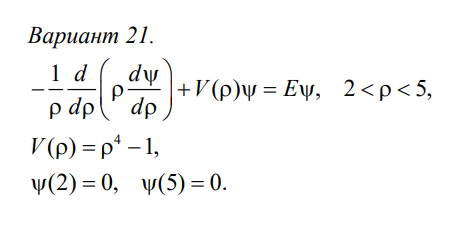

Промежуточные выкладки:
    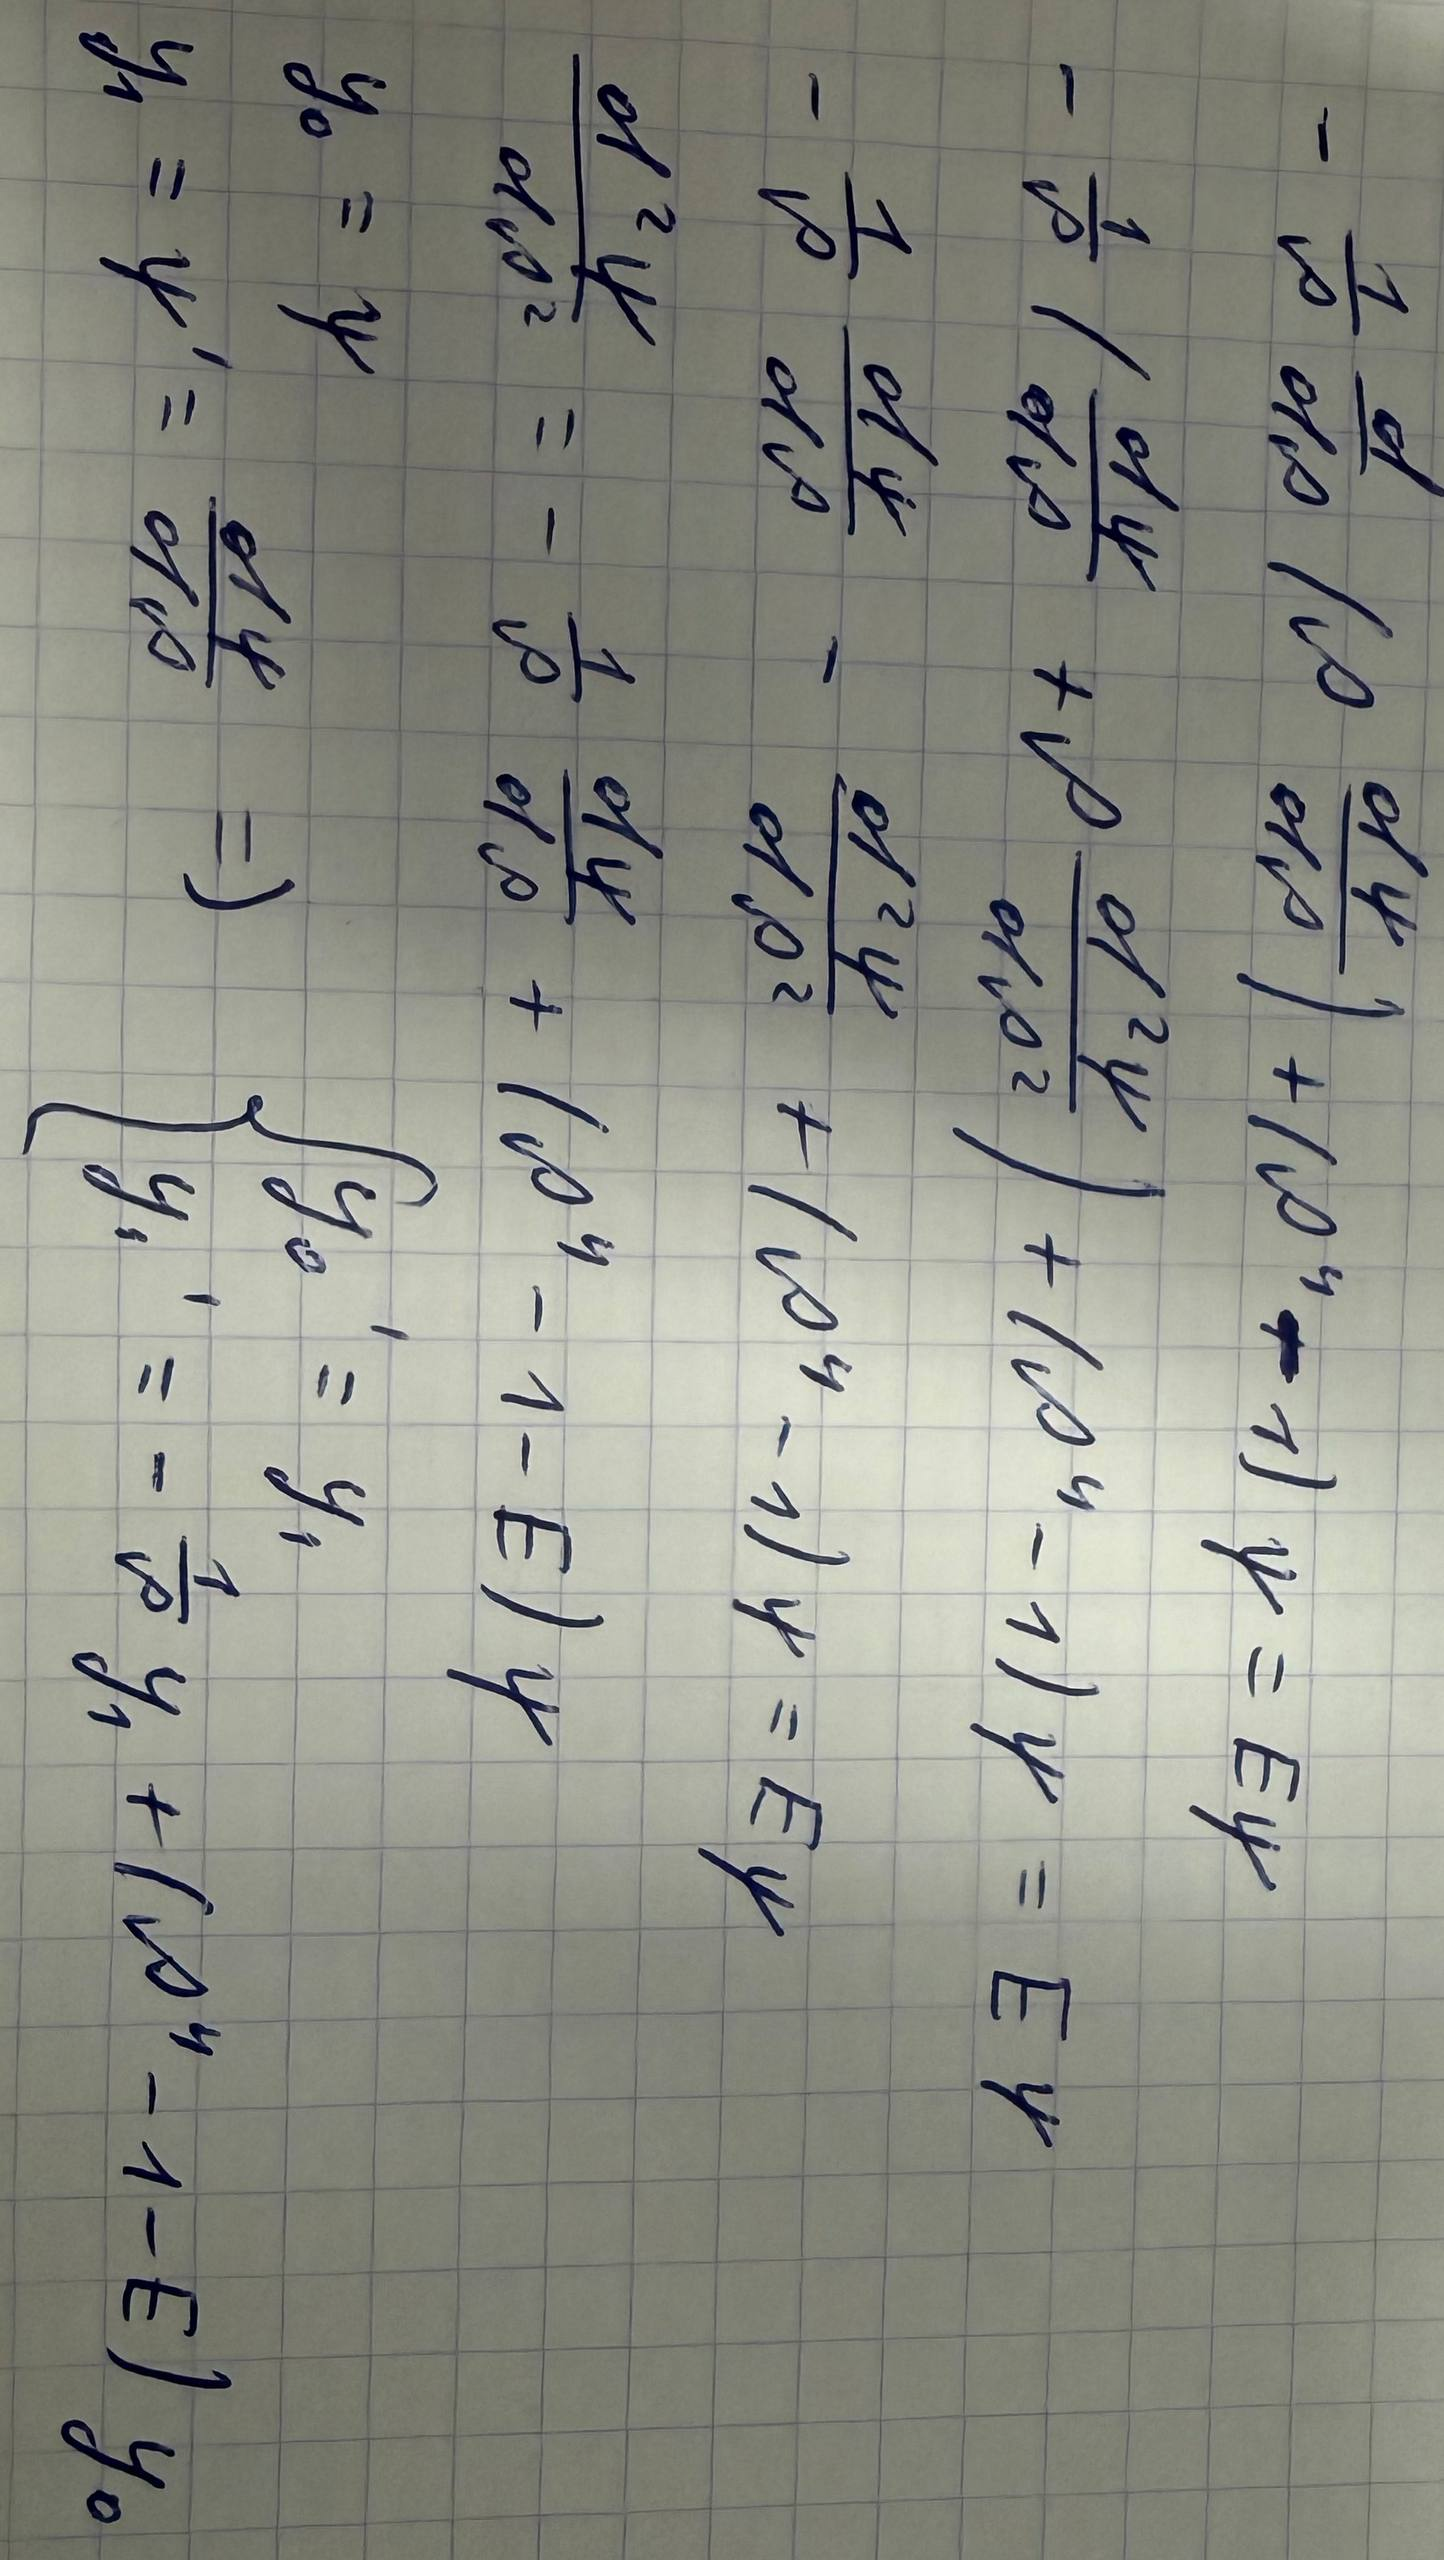

Найденная энергия E = 45.060484


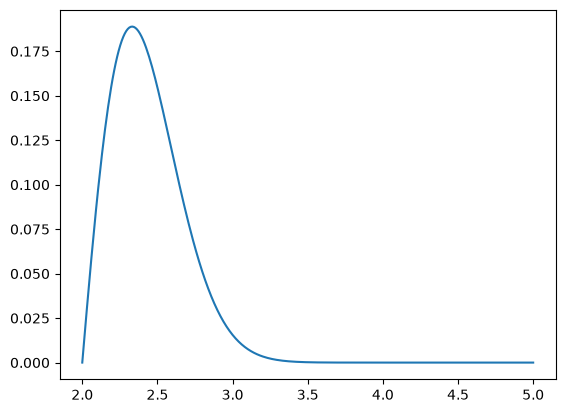

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

def dydx(rho, y, p):
    E = p[0]
    return (y[1], -(1/rho)*y[1] + (rho**4 - 1 - E)*y[0])

def bc_fun(ya, yb, p):
    return ya[0], yb[0], ya[1] - 1.0

rho = np.linspace(2, 5, 100)
y = np.zeros((2, rho.size))
y[0] = (rho - 2) * (5 - rho) 
p_guess = [10.0]
sol = solve_bvp(dydx, bc_fun, rho, y, p=p_guess, tol=1e-5)
print(f"Найденная энергия E = {sol.p[0]:.6f}")
plt.plot(sol.x, sol.y[0])

Найденная энергия E = 30.000000


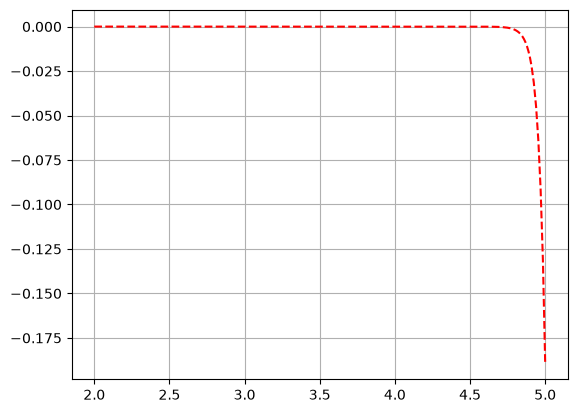

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp
from scipy.integrate import solve_ivp

def dydx_ivp(rho, y, E):
    return [y[1], -(1/rho)*y[1] + (rho**4 - 1 - E)*y[0]]

def shoot(E):
    y0 = [0.0, 1.0]
    sol_ivp = solve_ivp(dydx_ivp, [2, 5], y0, args=(E,), rtol=1e-5)
    return sol_ivp.y[0, -1]

E1 = 0.0
E2 = 30.0
y1 = shoot(E1)
y2 = shoot(E2)

while abs(E2 - E1) > 1e-6:
    E3 = (E1 + E2) / 2
    y3 = shoot(E3)
    
    if y1 * y3 < 0:
        E2 = E3
        y2 = y3
    else:
        E1 = E3
        y1 = y3

E_shoot = (E1 + E2) / 2
print(f"Найденная энергия E = {E_shoot:.6f}")
sol_shoot = solve_ivp(dydx_ivp, [2, 5], [0.0, 1.0], args=(E_shoot,), t_eval=sol.x)
norm_bvp = np.max(np.abs(sol.y[0]))
norm_shoot = np.max(np.abs(sol_shoot.y[0]))

plt.plot(sol_shoot.t, -sol_shoot.y[0] * (norm_bvp / norm_shoot), 'r--')
plt.grid(True)
plt.show()